In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
tf.random.set_seed(42)


In [4]:
# Load the downloaded dataset
# Load the downloaded dataset
bike = pd.read_csv("bike+sharing+dataset/hour.csv")

print("Dataset loaded successfully.")
print("Rows and columns:", bike.shape)


Dataset loaded successfully.
Rows and columns: (17379, 17)


In [5]:
# Display the first five rows so we can see what the data looks like.
bike.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
#Understand the columns
print("Available columns:")
print(bike.columns.tolist())

print("\\nMissing values in the original columns:")
print(bike[["dteday", "hr", "cnt"]].isna().sum())

bike[["dteday", "hr", "cnt"]].head()

Available columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'timestamp']
\nMissing values in the original columns:
dteday    0
hr        0
cnt       0
dtype: int64


,dteday,hr,cnt
0,2011-01-01,0,16
1,2011-01-01,1,40
2,2011-01-01,2,32
3,2011-01-01,3,13
4,2011-01-01,4,1


In [ ]:
#Create a timestamp
bike["timestamp"] = (
    pd.to_datetime(bike["dteday"])
    + pd.to_timedelta(bike["hr"], unit="h")
)

bike = bike.sort_values("timestamp")

# Keep only the timestamp and the value we want to predict.
hourly = bike[["timestamp", "cnt"]].copy()
hourly = hourly.set_index("timestamp")

hourly.head()

,cnt
timestamp,
2011-01-01 00:00:00,16
2011-01-01 01:00:00,40
2011-01-01 02:00:00,32
2011-01-01 03:00:00,13
2011-01-01 04:00:00,1


In [ ]:
#Make the hourly timeline continuous

# If a timestamp appears more than once, combine its values.
hourly = hourly.groupby(level=0)["cnt"].mean().to_frame()

# Create one timestamp for every hour between the first and last observation.
complete_hours = pd.date_range(
    start=hourly.index.min(),
    end=hourly.index.max(),
    freq="h"
)

# Add missing hourly rows. Their rental counts remain NaN for now.
hourly = hourly.reindex(complete_hours)
hourly.index.name = "timestamp"

# Count missing observations, but do not interpolate or backward-fill them.
missing_hours = int(hourly["cnt"].isna().sum())
print("Missing hourly values after reindexing:", missing_hours)
print("Hourly rows after preparation:", len(hourly))
print("Missing counts kept for now:", int(hourly["cnt"].isna().sum()))

hourly.head()


Missing hourly values after reindexing: 165
Hourly rows after preparation: 17544
Missing counts kept for now: 165


,cnt
timestamp,
2011-01-01 00:00:00,16.0
2011-01-01 01:00:00,40.0
2011-01-01 02:00:00,32.0
2011-01-01 03:00:00,13.0
2011-01-01 04:00:00,1.0


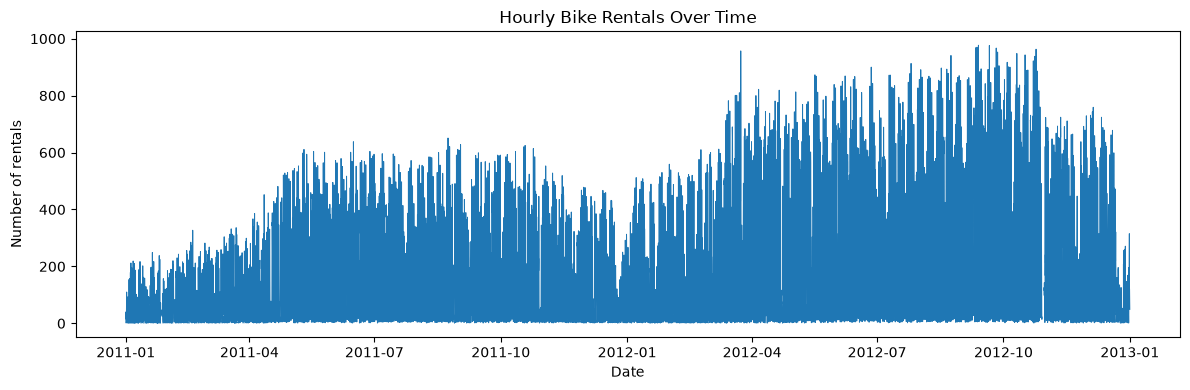

In [ ]:
#Explore the demand pattern

plt.figure(figsize=(12, 4))
plt.plot(hourly.index, hourly["cnt"], linewidth=0.7)
plt.title("Hourly Bike Rentals Over Time")
plt.xlabel("Date")
plt.ylabel("Number of rentals")
plt.tight_layout()
plt.show()

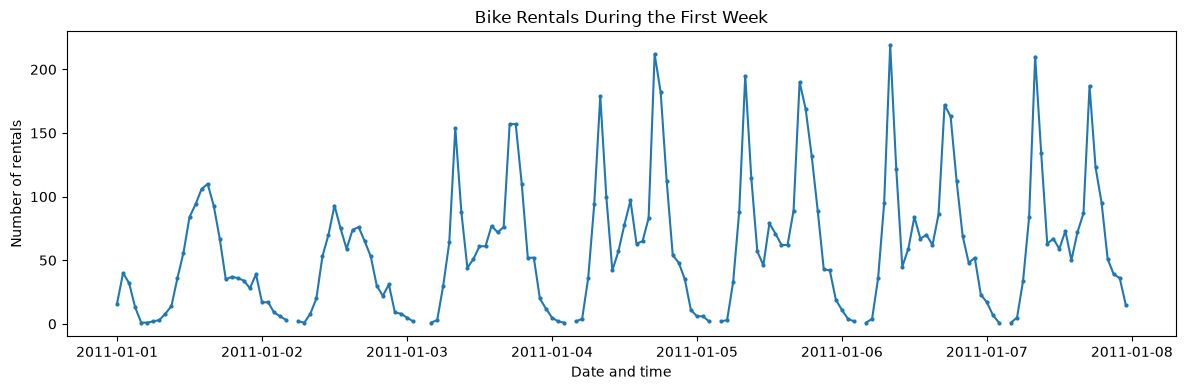

In [11]:
# Zoom in on the first seven days to see the within-day pattern.
first_week = hourly.iloc[:24 * 7]

plt.figure(figsize=(12, 4))
plt.plot(first_week.index, first_week["cnt"], marker="o", markersize=2)
plt.title("Bike Rentals During the First Week")
plt.xlabel("Date and time")
plt.ylabel("Number of rentals")
plt.tight_layout()
plt.show()

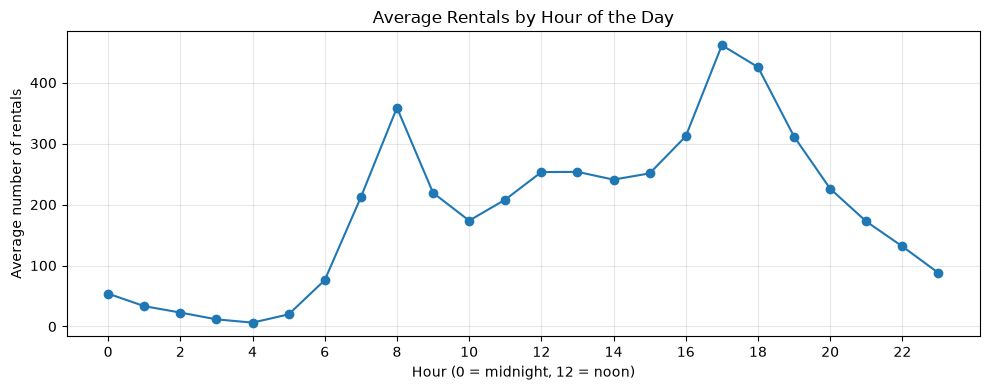

In [12]:
# Average rentals for each hour of the day across the full dataset.
average_by_hour = hourly.groupby(hourly.index.hour)["cnt"].mean()

plt.figure(figsize=(10, 4))
plt.plot(average_by_hour.index, average_by_hour.values, marker="o")
plt.title("Average Rentals by Hour of the Day")
plt.xlabel("Hour (0 = midnight, 12 = noon)")
plt.ylabel("Average number of rentals")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
#Define the forecasting task

LOOKBACK = 24 * 7   # Previous 7 days = 168 hours
HORIZON = 24        # Predict the next 24 hours

print("Input length:", LOOKBACK, "hours")
print("Output length:", HORIZON, "hours")

Input length: 168 hours
Output length: 24 hours


In [14]:
#Split the data in time order

values = hourly[["cnt"]].astype("float32").values
n_hours = len(values)

# Round split points down to full-day boundaries.
train_end = (int(n_hours * 0.70) // 24) * 24
val_end = (int(n_hours * 0.85) // 24) * 24

print("Total hourly observations:", n_hours)
print("Training ends at row:", train_end)
print("Validation ends at row:", val_end)
print("Training period:", hourly.index[0], "to", hourly.index[train_end - 1])
print("Validation period:", hourly.index[train_end], "to", hourly.index[val_end - 1])
print("Test period:", hourly.index[val_end], "to", hourly.index[-1])

Total hourly observations: 17544
Training ends at row: 12264
Validation ends at row: 14904
Training period: 2011-01-01 00:00:00 to 2012-05-25 23:00:00
Validation period: 2012-05-26 00:00:00 to 2012-09-12 23:00:00
Test period: 2012-09-13 00:00:00 to 2012-12-31 23:00:00


In [15]:
#Scale the values

# Keep the original rental counts. Missing observations remain NaN.
values = hourly[["cnt"]].astype("float32").values

# Use only observed counts in the training period to fit the scaler.
train_values = values[:train_end]
train_values = train_values[np.isfinite(train_values[:, 0])]

if len(train_values) == 0:
    raise ValueError("No observed rental counts found in the training period.")

scaler = MinMaxScaler()
scaler.fit(train_values)

# Prepare historical model inputs using only previous observations.
# Forward fill uses the latest earlier count; it never looks ahead.
input_series = pd.Series(values[:, 0], index=hourly.index).ffill()

# A leading missing value cannot be forward-filled, so check for it.
if input_series.isna().any():
    raise ValueError(
        "Missing counts remain at the start of the series. "
        "Inspect the first rows before continuing."
    )

input_values = input_series.to_numpy(dtype="float32").reshape(-1, 1)

# Scale the complete input series using the scaler fitted on training data.
scaled_values = scaler.transform(input_values).astype("float32")

# Scale targets separately but preserve NaN values for missing observations.
# MinMaxScaler.transform keeps NaNs as NaNs.
scaled_target_values = scaler.transform(values).astype("float32")

print("Training minimum used by scaler:", float(scaler.data_min_[0]))
print("Training maximum used by scaler:", float(scaler.data_max_[0]))
print("Missing values in model inputs:", int(np.isnan(scaled_values).sum()))
print("Missing values retained in targets:", int(np.isnan(scaled_target_values).sum()))
print("First five scaled input values:", scaled_values[:5].flatten())


Training minimum used by scaler: 1.0
Training maximum used by scaler: 957.0
Missing values in model inputs: 0
Missing values retained in targets: 165
First five scaled input values: [0.01569038 0.04079498 0.03242678 0.0125523  0.        ]


In [16]:
#Create input/output sequences

# Create one example: 168 past hourly values -> next 24 hourly targets.
def make_windows(input_data, target_data, first_target_start, target_end_limit):
    X, y, forecast_starts = [], [], []

    # Start each forecast one day (24 hours) after the previous one.
    for target_start in range(LOOKBACK, len(input_data) - HORIZON + 1, 24):
        target_end = target_start + HORIZON

        # Keep the target entirely inside the requested split.
        if target_start < first_target_start or target_end > target_end_limit:
            continue

        # These are the 24 true target values, before any imputation.
        target = target_data[target_start:target_end, 0]

        # Skip this example if even one of the next 24 counts is missing.
        if not np.isfinite(target).all():
            continue

        # Input: the 168 preceding hours (missing inputs were forward-filled).
        X.append(input_data[target_start - LOOKBACK:target_start])

        # Target: the following 24 observed hourly counts.
        y.append(target)

        # Save the timestamp when the forecast starts.
        forecast_starts.append(hourly.index[target_start])

    return (
        np.array(X, dtype="float32"),
        np.array(y, dtype="float32"),
        pd.DatetimeIndex(forecast_starts)
    )


# Build windows separately for training, validation and testing.
X_train, y_train, train_dates = make_windows(
    scaled_values, scaled_target_values, LOOKBACK, train_end
)

X_val, y_val, val_dates = make_windows(
    scaled_values, scaled_target_values, train_end, val_end
)

X_test, y_test, test_dates = make_windows(
    scaled_values, scaled_target_values, val_end, len(scaled_values)
)

# Print the actual number of examples retained in each split.
print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)
print("Validation inputs:", X_val.shape)
print("Validation targets:", y_val.shape)
print("Test inputs:", X_test.shape)
print("Test targets:", y_test.shape)


Training inputs: (440, 168, 1)
Training targets: (440, 24)
Validation inputs: (110, 168, 1)
Validation targets: (110, 24)
Test inputs: (104, 168, 1)
Test targets: (104, 24)


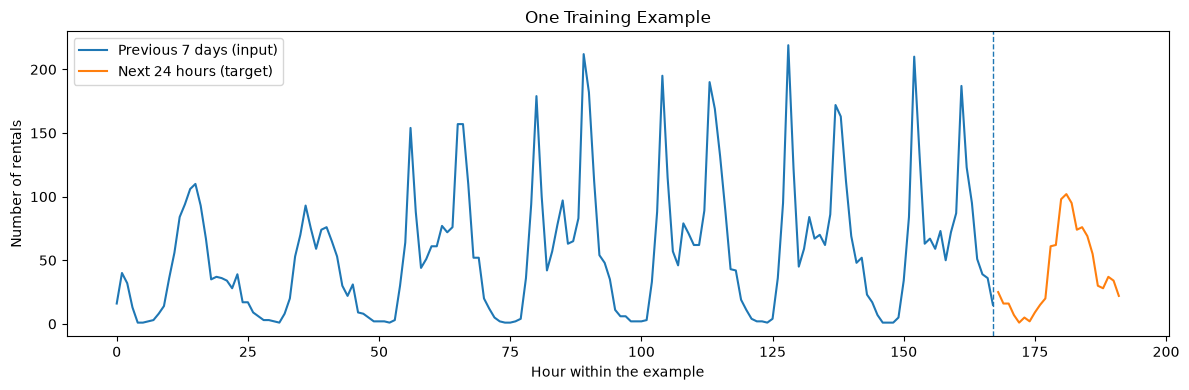

In [17]:
# Visualise one example of the input and the target the model must predict.
sample_number = 0

sample_input = scaler.inverse_transform(X_train[sample_number]).flatten()
sample_target = scaler.inverse_transform(y_train[sample_number].reshape(-1, 1)).flatten()

plt.figure(figsize=(12, 4))
plt.plot(range(LOOKBACK), sample_input, label="Previous 7 days (input)")
plt.plot(range(LOOKBACK, LOOKBACK + HORIZON), sample_target,
         label="Next 24 hours (target)")
plt.axvline(LOOKBACK - 1, linestyle="--", linewidth=1)
plt.title("One Training Example")
plt.xlabel("Hour within the example")
plt.ylabel("Number of rentals")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
#Build a simple baseline

def previous_day_baseline(X):
    """Use the last 24 input values as the next 24-hour forecast."""
    return X[:, -HORIZON:, 0]

baseline_val_scaled = previous_day_baseline(X_val)
baseline_test_scaled = previous_day_baseline(X_test)

print("Baseline forecast shape:", baseline_test_scaled.shape)

Baseline forecast shape: (104, 24)


In [19]:
#Define the neural network models

def build_model(model_name):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(LOOKBACK, 1)))

    if model_name == "SimpleRNN":
        model.add(tf.keras.layers.SimpleRNN(32))
    elif model_name == "LSTM":
        model.add(tf.keras.layers.LSTM(32))
    elif model_name == "GRU":
        model.add(tf.keras.layers.GRU(32))
    else:
        raise ValueError("model_name must be 'SimpleRNN', 'LSTM', or 'GRU'")

    # Predict all 24 hours in one step.
    model.add(tf.keras.layers.Dense(HORIZON))

    model.compile(optimizer="adam", loss="mae", metrics=["mae"])
    return model

# Inspect one model's architecture before training.
example_model = build_model("LSTM")
example_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,144 (20.09 KB)

 Trainable params: 5,144 (20.09 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
#Train Simple RNN, LSTM, and GRU

model_names = ["SimpleRNN", "LSTM", "GRU"]
models = {}
histories = {}
training_seconds = {}

for model_name in model_names:
    print(f"\\nTraining {model_name}...")

    tf.keras.backend.clear_session()
    model = build_model(model_name)

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    start_time = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=5,
        batch_size=32,
        callbacks=[early_stopping],
        shuffle=False,
        verbose=1
    )
    training_seconds[model_name] = time.perf_counter() - start_time
    models[model_name] = model
    histories[model_name] = history

    print(f"{model_name} training time: {training_seconds[model_name]:.1f} seconds")

\nTraining SimpleRNN...

Epoch 1/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.1710 - mae: 0.1710 - val_loss: 0.2427 - val_mae: 0.2427
Epoch 2/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1204 - mae: 0.1204 - val_loss: 0.1801 - val_mae: 0.1801
Epoch 3/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0939 - mae: 0.0939 - val_loss: 0.1451 - val_mae: 0.1451
Epoch 4/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0813 - mae: 0.0813 - val_loss: 0.1325 - val_mae: 0.1325
Epoch 5/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0746 - mae: 0.0746 - val_loss: 0.1254 - val_mae: 0.1254
SimpleRNN training time: 5.1 seconds
\nTraining LSTM...
Epoch 1/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - loss: 0.1600 - mae: 0.1600 - val_loss: 0.2461 - val_mae: 0.2461
Epoch 2/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.1203 - mae: 0.1203 - val_loss: 0.1683 - val_mae: 0.1683
Epoch 3/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0929 - mae: 0.0929 - val_loss: 0.1360 - val_mae

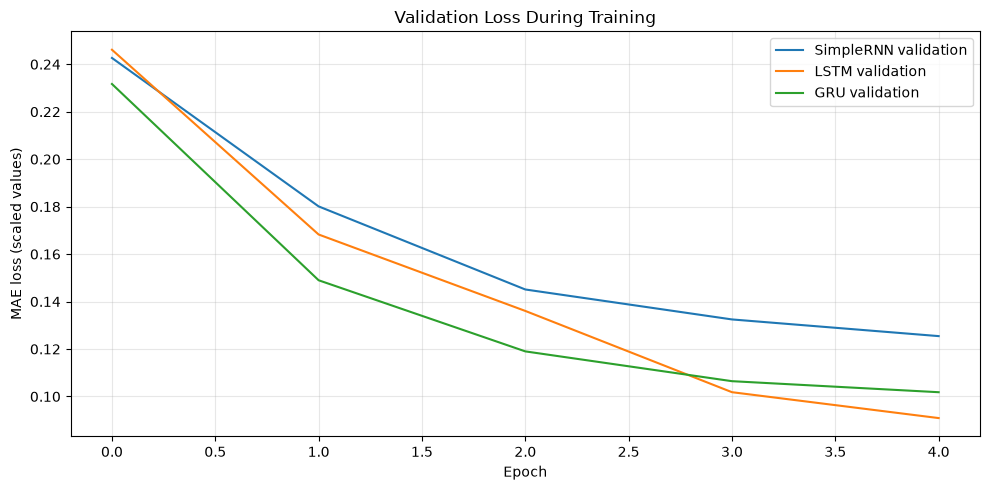

In [21]:
#Compare learning curves

plt.figure(figsize=(10, 5))

for model_name, history in histories.items():
    plt.plot(history.history["val_loss"], label=f"{model_name} validation")

plt.title("Validation Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("MAE loss (scaled values)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
#Convert predictions back to rental counts

def to_rental_counts(scaled_data):
    """Convert an array of scaled values back to original rental counts."""
    original_shape = scaled_data.shape
    values_2d = scaled_data.reshape(-1, 1)
    counts = scaler.inverse_transform(values_2d)
    return counts.reshape(original_shape)


y_val_counts = to_rental_counts(y_val)
y_test_counts = to_rental_counts(y_test)

print("First 5 actual values in the first test day:")
print(np.round(y_test_counts[0], 0).astype(int)[:5])

First 5 actual values in the first test day:
[57 28  9 11  6]


In [23]:
#Evaluate the models

def calculate_metrics(actual, predicted):
    actual_flat = actual.reshape(-1)
    predicted_flat = predicted.reshape(-1)

    mae = mean_absolute_error(actual_flat, predicted_flat)
    rmse = np.sqrt(mean_squared_error(actual_flat, predicted_flat))
    return {"MAE": mae, "RMSE": rmse}


# Evaluate the previous-day baseline.
baseline_val_counts = to_rental_counts(baseline_val_scaled)
baseline_test_counts = to_rental_counts(baseline_test_scaled)

validation_predictions = {"Previous-day baseline": baseline_val_counts}
test_predictions = {"Previous-day baseline": baseline_test_counts}

# Predict with each trained neural network.
for model_name, model in models.items():
    val_pred_scaled = model.predict(X_val, verbose=0)
    test_pred_scaled = model.predict(X_test, verbose=0)

    validation_predictions[model_name] = to_rental_counts(val_pred_scaled)
    test_predictions[model_name] = to_rental_counts(test_pred_scaled)


results = []
for name in validation_predictions:
    val_metrics = calculate_metrics(y_val_counts, validation_predictions[name])
    test_metrics = calculate_metrics(y_test_counts, test_predictions[name])

    results.append({
        "Model": name,
        "Validation MAE": val_metrics["MAE"],
        "Validation RMSE": val_metrics["RMSE"],
        "Test MAE": test_metrics["MAE"],
        "Test RMSE": test_metrics["RMSE"],
        "Training time (sec)": 0 if name == "Previous-day baseline" else training_seconds[name]
    })

results_df = pd.DataFrame(results).sort_values("Validation MAE").reset_index(drop=True)
results_df.round(2)

,Model,Validation MAE,Validation RMSE,Test MAE,Test RMSE,Training time (sec)
0,Previous-day baseline,82.19,137.43,80.00,132.88,0.00
1,LSTM,86.89,126.56,84.09,129.17,7.19
2,GRU,97.31,142.21,91.36,138.04,8.23
3,SimpleRNN,119.92,161.35,96.45,141.62,5.05


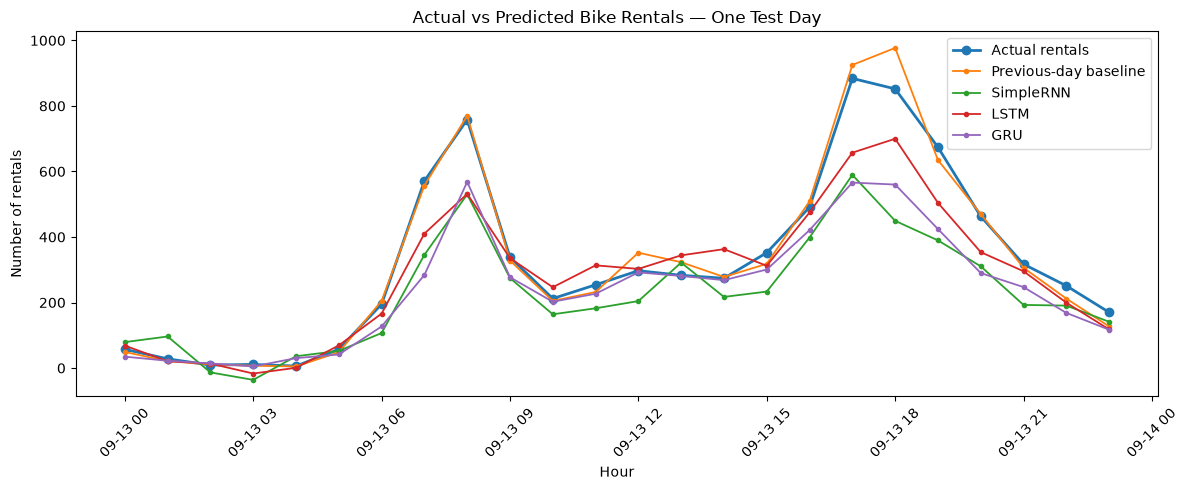

In [24]:
#Plot one 24-hour test forecast

day_number = 0  # Change this number to inspect another test day.
forecast_times = pd.date_range(test_dates[day_number], periods=HORIZON, freq="h")

plt.figure(figsize=(12, 5))
plt.plot(forecast_times, y_test_counts[day_number], marker="o",
         linewidth=2, label="Actual rentals")

for name, prediction in test_predictions.items():
    plt.plot(forecast_times, prediction[day_number], marker=".",
             linewidth=1.3, label=name)

plt.title("Actual vs Predicted Bike Rentals — One Test Day")
plt.xlabel("Hour")
plt.ylabel("Number of rentals")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
#Select a model using validation data

neural_model_names = list(models.keys())

best_model_name = min(
    neural_model_names,
    key=lambda name: calculate_metrics(
        y_val_counts, validation_predictions[name]
    )["MAE"]
)

best_model = models[best_model_name]
best_val_mae = calculate_metrics(
    y_val_counts, validation_predictions[best_model_name]
)["MAE"]
baseline_val_mae = calculate_metrics(
    y_val_counts, validation_predictions["Previous-day baseline"]
)["MAE"]

print("Best neural network by validation MAE:", best_model_name)
print(f"Its validation MAE: {best_val_mae:.2f} bikes per hour")
print(f"Baseline validation MAE: {baseline_val_mae:.2f} bikes per hour")

if best_val_mae < baseline_val_mae:
    print("The selected neural network beats the baseline on validation data.")
else:
    print("The neural network does not beat the baseline on validation data.")

Best neural network by validation MAE: LSTM
Its validation MAE: 86.89 bikes per hour
Baseline validation MAE: 82.19 bikes per hour
The neural network does not beat the baseline on validation data.


In [26]:
#Forecast the next 24 hours after the dataset

latest_window = scaled_values[-LOOKBACK:].reshape(1, LOOKBACK, 1)
future_scaled = best_model.predict(latest_window, verbose=0)
future_counts = to_rental_counts(future_scaled).flatten()

future_times = pd.date_range(
    start=hourly.index[-1] + pd.Timedelta(hours=1),
    periods=HORIZON,
    freq="h"
)

forecast_df = pd.DataFrame({
    "timestamp": future_times,
    "predicted_rentals": np.maximum(future_counts, 0).round().astype(int)
})

forecast_df.head(10)

,timestamp,predicted_rentals
0,2013-01-01 00:00:00,43
1,2013-01-01 01:00:00,13
2,2013-01-01 02:00:00,16
3,2013-01-01 03:00:00,8
4,2013-01-01 04:00:00,0
5,2013-01-01 05:00:00,16
6,2013-01-01 06:00:00,57
7,2013-01-01 07:00:00,190
8,2013-01-01 08:00:00,243
9,2013-01-01 09:00:00,152


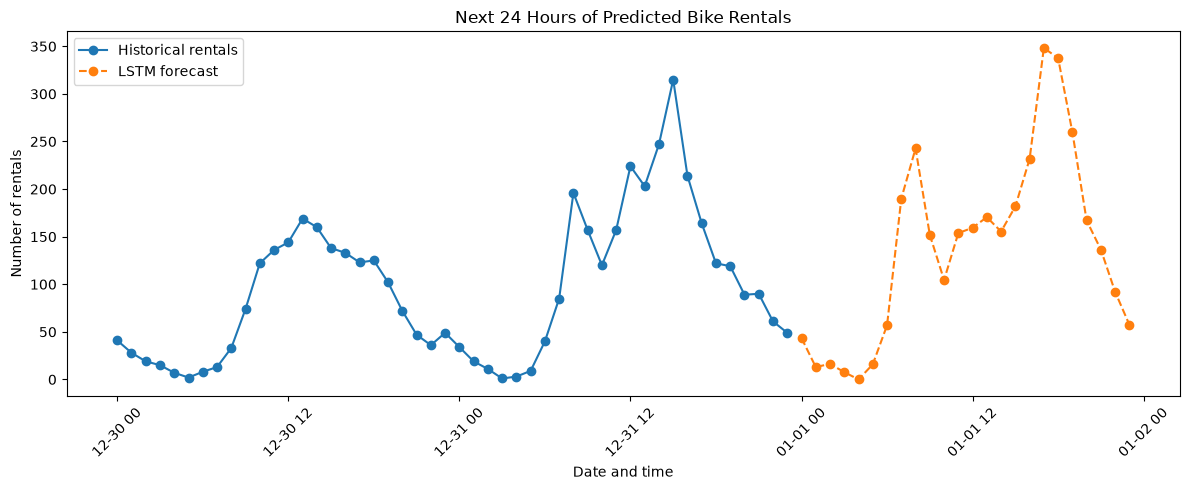

In [27]:
plt.figure(figsize=(12, 5))

# Show the last 48 observed hours for context.
recent_history = hourly.iloc[-48:]
plt.plot(recent_history.index, recent_history["cnt"],
         marker="o", label="Historical rentals")
plt.plot(future_times, np.maximum(future_counts, 0),
         marker="o", linestyle="--", label=f"{best_model_name} forecast")

plt.title("Next 24 Hours of Predicted Bike Rentals")
plt.xlabel("Date and time")
plt.ylabel("Number of rentals")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()